In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'data' / '3_train.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'data' / '3_val.parquet')
train_kf_oof = pd.read_parquet(PROJECT_ROOT / 'data' / '0_kf_oof.parquet')

In [2]:
# ============================================================
# 1. 최종 컬럼군 정의
# ============================================================

# 종속변수군
target_col = 'target_maxrise_6h'

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 독립변수군
feature_cols = [
    col for col in train.columns
    if col not in rain_int_cols + ['timestamp', 'event_id', target_col]
]

assert len(feature_cols) == 28, (
    f'독립변수 개수 이상: 예상 28개, 현재 {len(feature_cols)}개'
)

In [3]:
# ============================================================
# 2. OOF 잔차 생성
# ============================================================

train_kf_oof['resid'] = train_kf_oof['y_train'] - train_kf_oof['y_pred']
train_kf_oof['resid_sq'] = train_kf_oof['resid'] ** 2
train_kf_oof['resid_abs'] = train_kf_oof['resid'].abs()

train_kf_oof.head()

,event_id,y_train,y_pred,fold,resid,resid_sq,resid_abs
row_id,,,,,,,
TR_000222241,1,0.00,0.028109,5,-0.028109,0.000790,0.028109
TR_000288748,1,0.00,0.003864,5,-0.003864,0.000015,0.003864
TR_000737576,1,0.00,0.014299,5,-0.014299,0.000204,0.014299
TR_000651952,1,0.00,-0.008879,5,0.008879,0.000079,0.008879
TR_000328380,1,0.03,0.055385,5,-0.025385,0.000644,0.025385


In [ ]:
# ============================================================
# 2. 종속변수 구간별 오차분석: OOF 전체
# ============================================================

import numpy as np

# 종속변수 분위수 기준으로 구간 설정
q = [0, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]
labels = ['0~50%', '50~75%', '75~90%', '90~95%', '95~99%', '99~100%']

train_kf_oof['y_train_quant'] = pd.qcut(  # q분위수 기준으로 구간 나누기, 구간별 라벨 붙이는 함수
    train_kf_oof['y_train'],  # 매개변수: 구간을 나눌 기준 데이터
    q=q,  # 구간을 나눌 위치(분위수)
    labels=labels # 구간별 값 지정(q보다 하나 적어야 함)
)

# 구간별 RMSE 계산
rmse_y_train_segment = (
    train_kf_oof
    .groupby('y_train_quant', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        mse=('resid_sq', 'mean'),  # 잔차제곱의 평균 = mse, 루트하면 rmse
        sse=('resid_sq', 'sum')
    )
)

rmse_y_train_segment['rmse'] = np.sqrt(rmse_y_train_segment['mse'])
rmse_y_train_segment['sse_pct(%)'] = (
    rmse_y_train_segment['sse']/
    rmse_y_train_segment['sse'].sum()
    *100
)

display(rmse_y_train_segment[['count', 'rmse', 'sse','sse_pct(%)']])

,count,rmse,sse,sse_pct(%)
y_train_quant,,,,
0~50%,340940,0.096909,3201.857307,9.648810
50~75%,127705,0.094898,1150.057611,3.465703
75~90%,87488,0.158383,2194.650339,6.613588
90~95%,29345,0.281637,2327.620578,7.014294
95~99%,24674,0.651542,10474.274399,31.564269
99~100%,6141,1.500990,13835.499620,41.693335


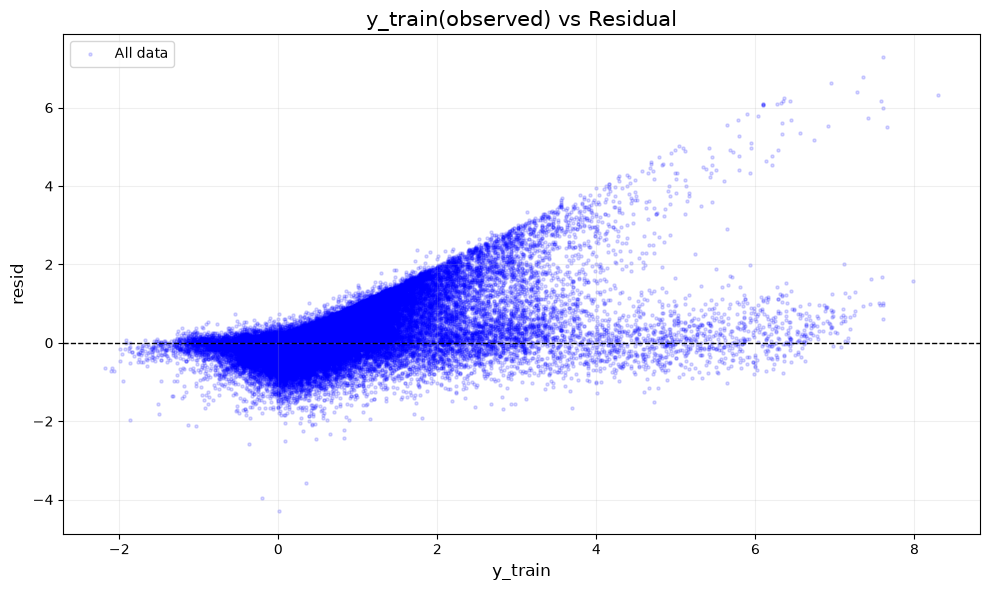

전체 데이터: 616,293


In [ ]:
# ============================================================
# 2-1. 실제값 - 예측잔차 산점도
# ============================================================

# 1. 분석 설정
df = train_kf_oof          # 분석 데이터(전체)
x_col = 'y_train'         # X축: 실제값
y_col = 'resid'         # Y축: 예측잔차
plot_title = 'y_train(observed) vs Residual'

# # 2. 강조 조건 설정 (True = 전체 데이터)
# cond = (
#     (df['station_id'] == 101)
#     # & (df['hour'] >= 12)
#     # & (df['hour'] < 18)
# )

# # 3. 조건별 데이터 구분
# highlight = df.loc[cond]   # 빨간색 강조 데이터

# 4. 산점도
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# 전체 데이터: 회색
ax.scatter(
    df[x_col], df[y_col],
    color='blue', alpha=0.15, s=5,
    label='All data'
)

# # 조건 데이터: 빨간색
# ax.scatter(
#     highlight[x_col], highlight[y_col],
#     color='red', alpha=0.7, s=10,
#     label=f'Highlighted (n={len(highlight):,})'
# )

# 5. 그래프 설정
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title(plot_title, fontsize=15)
ax.set_xlabel(x_col, fontsize=12)
ax.set_ylabel(y_col, fontsize=12)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 6. 강조 데이터 확인
print(f"전체 데이터: {len(df):,}")
# print(f"강조 데이터: {len(highlight):,}")
# print(f"강조 비율: {len(highlight)/len(df):.2%}")

In [ ]:
# ============================================================
# 3-1. 관측소별 RMSE: OOF 전체: 'station_id' 컬럼 추가
# ============================================================

assert train_kf_oof.index.equals(train.index), "train_kf_oof 인덱스 이상"
train_kf_oof['station_id'] = train['station_id']

train_kf_oof.head()

,event_id,y_train,y_pred,fold,resid,resid_sq,resid_abs,y_train_quant,station_id
row_id,,,,,,,,,
TR_000222241,1,0.00,0.028109,5,-0.028109,0.000790,0.028109,0~50%,ST0001
TR_000288748,1,0.00,0.003864,5,-0.003864,0.000015,0.003864,0~50%,ST0002
TR_000737576,1,0.00,0.014299,5,-0.014299,0.000204,0.014299,0~50%,ST0003
TR_000651952,1,0.00,-0.008879,5,0.008879,0.000079,0.008879,0~50%,ST0004
TR_000328380,1,0.03,0.055385,5,-0.025385,0.000644,0.025385,50~75%,ST0005


In [20]:
# ============================================================
# 3-2. 관측소별 오차분석: OOF 전체
# ============================================================

# 'station_id' 컬럼 생성
assert train_kf_oof.index.equals(train.index), "train_kf_oof 인덱스 이상"
train_kf_oof['station_id'] = train['station_id']

# 관측소별 RMSE 계산
station_error_stats = (
    train_kf_oof
    .groupby('station_id')
    .agg(
        count=('resid_sq', 'count'),
        SSE=('resid_sq', 'sum'),
        MSE=('resid_sq', 'mean')
    )    
)

import numpy as np
station_error_stats['RMSE'] = np.sqrt(station_error_stats['MSE'])
station_error_stats['SSE_pct(%)'] = (
        station_error_stats['SSE']
        / station_error_stats['SSE'].sum()
        * 100
)

display(station_error_stats.sort_values('SSE_pct(%)', ascending=False).head(10))

n = 10
print(f'상위 {n}개 누적 SSE_pct(%): ', station_error_stats.nlargest(n, 'SSE_pct(%)')['SSE_pct(%)'].sum())



,count,SSE,MSE,RMSE,SSE_pct(%)
station_id,,,,,
ST0028,1379,404.652397,0.293439,0.541700,1.219422
ST0445,991,389.049011,0.392582,0.626564,1.172401
ST0159,1379,379.175821,0.274964,0.524370,1.142648
ST0428,1379,365.444535,0.265007,0.514788,1.101269
ST0313,1379,333.453765,0.241808,0.491740,1.004864
ST0412,1379,314.277841,0.227903,0.477392,0.947078
ST0448,1360,307.103101,0.225811,0.475196,0.925456
ST0095,1379,305.597958,0.221608,0.470753,0.920921
ST0221,1379,290.994439,0.211018,0.459367,0.876913


상위 10개 누적 SSE_pct(%):  10.157695168011005


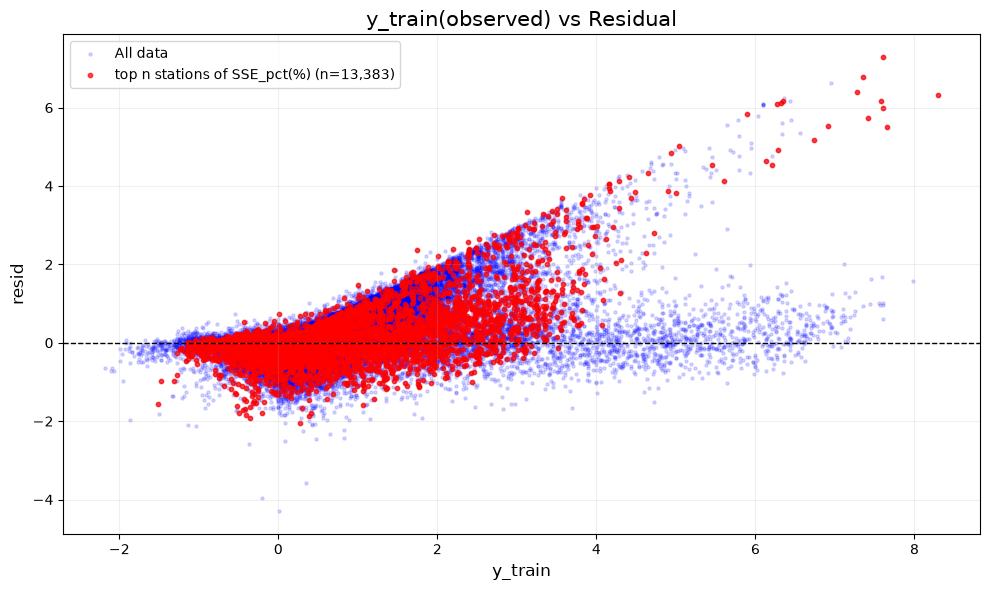

전체 데이터: 616,293
강조 데이터: 13,383
강조 비율: 2.17%


In [ ]:
# ============================================================
# 3-3. SSE 상위 관측소, 실제값 - 예측잔차 산점도
# ============================================================
# 결과: 의외로 고잔차 데이터를 충분히 설명하지 못함(상위 10개의 SSE 기여율 2.17%)

# 1. 분석 설정
df = train_kf_oof          # 분석 데이터(전체)
x_col = 'y_train'         # X축: 실제값
y_col = 'resid'         # Y축: 예측잔차
plot_title = 'y_train(observed) vs Residual'

# 2. 강조 조건 설정 (True = 전체 데이터)
cond = df['station_id'].isin(
    station_error_stats.nlargest(
        10, 'SSE_pct(%)').index)  # station_error_stats의 'event_id'는 인덱스임


# 3. 조건별 데이터 구분
highlight = df.loc[cond]   # 빨간색 강조 데이터

# 4. 산점도
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# 전체 데이터: 회색
ax.scatter(
    df[x_col], df[y_col],
    color='blue', alpha=0.15, s=5,
    label='All data'
)

# 조건 데이터: 빨간색
ax.scatter(
    highlight[x_col], highlight[y_col],
    color='red', alpha=0.7, s=10,
    label=f'top n stations of SSE_pct(%) (n={len(highlight):,})'
)

# 5. 그래프 설정
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title(plot_title, fontsize=15)
ax.set_xlabel(x_col, fontsize=12)
ax.set_ylabel(y_col, fontsize=12)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 6. 강조 데이터 확인
print(f"전체 데이터: {len(df):,}")
print(f"강조 데이터: {len(highlight):,}")
print(f"강조 비율: {len(highlight)/len(df):.2%}")

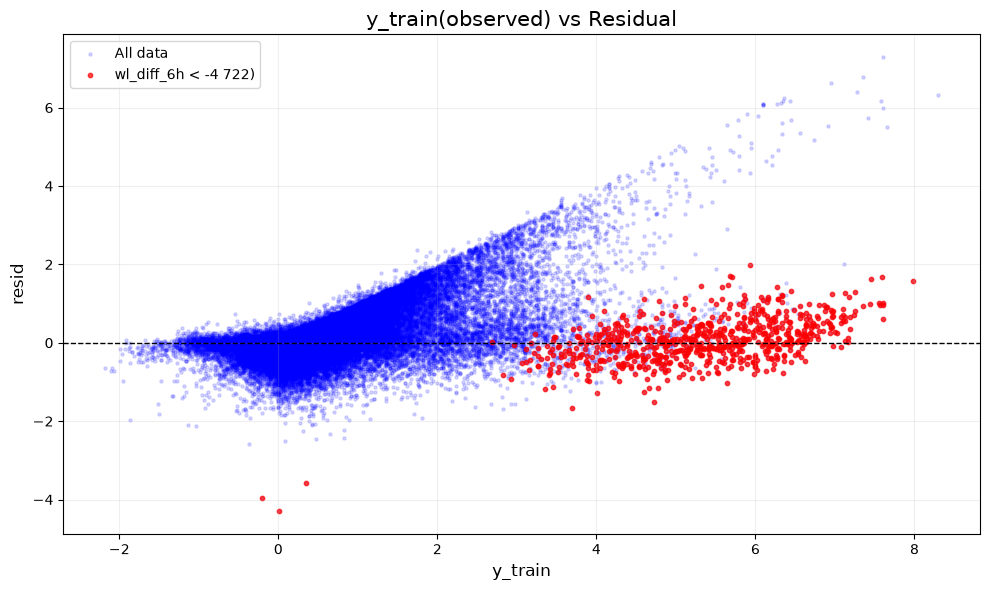

전체 데이터: 616,293
강조 데이터: 722
강조 비율: 0.12%


In [ ]:
# ============================================================
# 3-4. wl_diff_6h < 0 구간 하이라이트, 실제값 - 예측잔차 산점도
# ============================================================
# 결과: 예전부터 의심했던 오계측 구간은 예측력이 높음

# 1. 분석 설정
df = train_kf_oof          # 분석 데이터(전체)
x_col = 'y_train'         # X축: 실제값
y_col = 'resid'         # Y축: 예측잔차
plot_title = 'y_train(observed) vs Residual'

# 2. 강조 조건 설정 (True = 전체 데이터)
cond = df.index.isin(
    train.loc[train['wl_diff_6h'] < -4].index)  # station_error_stats의 'event_id'는 인덱스임

# 3. 조건별 데이터 구분
highlight = df.loc[cond]   # 빨간색 강조 데이터

# 4. 산점도
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# 전체 데이터: 회색
ax.scatter(
    df[x_col], df[y_col],
    color='blue', alpha=0.15, s=5,
    label='All data'
)

# 조건 데이터: 빨간색
ax.scatter(
    highlight[x_col], highlight[y_col],
    color='red', alpha=0.7, s=10,
    label=f'wl_diff_6h < -4 (n={len(highlight):,})'
)

# 5. 그래프 설정
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title(plot_title, fontsize=15)
ax.set_xlabel(x_col, fontsize=12)
ax.set_ylabel(y_col, fontsize=12)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 6. 강조 데이터 확인
print(f"전체 데이터: {len(df):,}")
print(f"강조 데이터: {len(highlight):,}")
print(f"강조 비율: {len(highlight)/len(df):.2%}")

In [ ]:
# ============================================================
# 4-1. 강우사상별 오차분석
# ============================================================
# 결과: SSE_pct(%), RMSE 거동이 상이함, SSE_pct(%) 최상위 event_id는 count가 많아서일뿐 RMSE는 1등이 아님

# 강우사상별 RMSE 계산
event_error_stats = (
    train_kf_oof
    .groupby('event_id')
    .agg(
        count=('resid_sq', 'count'),
        SSE=('resid_sq', 'sum'),
        MSE=('resid_sq', 'mean')
    )    
)

import numpy as np
event_error_stats['RMSE'] = np.sqrt(event_error_stats['MSE'])
event_error_stats['SSE_pct(%)'] = (
        event_error_stats['SSE']
        / event_error_stats['SSE'].sum()
        * 100
)

display(event_error_stats.sort_values('SSE_pct(%)', ascending=False).head(10))

n = 10
print(f'상위 {n}개 누적 SSE_pct(%): ', event_error_stats.nlargest(n, 'SSE_pct(%)')['SSE_pct(%)'].sum())


,count,SSE,MSE,RMSE,SSE_pct(%)
event_id,,,,,
98,71567,7747.873207,0.108260,0.329030,23.348248
90,24970,3744.844801,0.149974,0.387264,11.285105
35,19967,3192.703317,0.159899,0.399874,9.621225
97,7408,3139.698865,0.423825,0.651019,9.461495
3,18059,2650.983534,0.146796,0.383139,7.988750
89,25289,2288.906030,0.090510,0.300849,6.897628
28,28931,968.731970,0.033484,0.182987,2.919278
7,18192,805.225635,0.044263,0.210387,2.426551
96,19530,783.606027,0.040123,0.200308,2.361400


상위 10개 누적 SSE_pct(%):  78.46805044763536


========== 상위 SSE_pct(%) 강조 산점도 ==========
전체 데이터: 616,293
강조 데이터: 96,537
강조 비율: 15.66%
========== 상위 RMSE 강조 산점도 ==========
전체 데이터: 616,293
강조 데이터: 75,977
강조 비율: 12.33%


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_4216\301837610.py:67: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


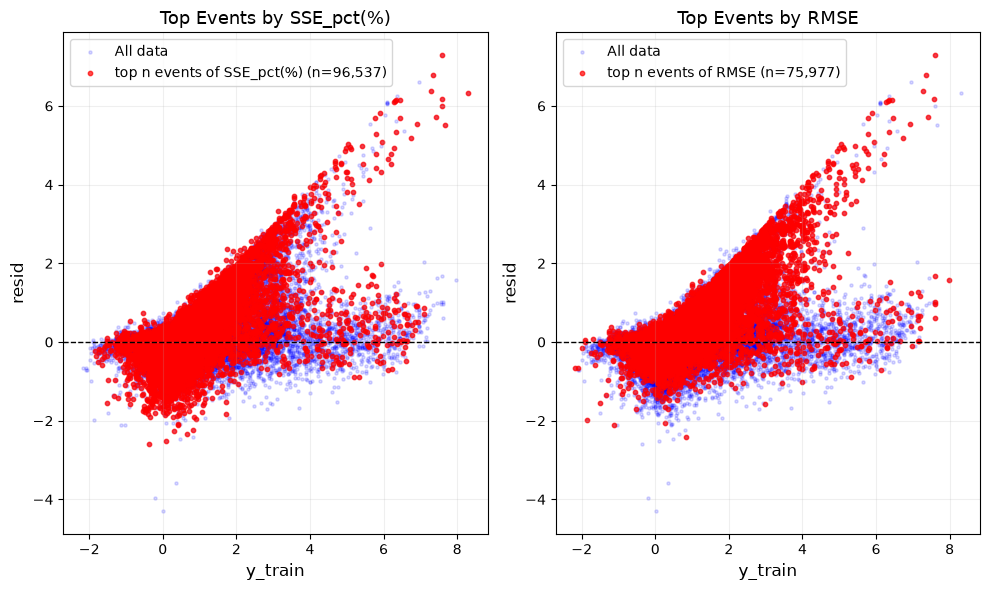

In [ ]:
# ============================================================
# # 4-2. 강우사상별 상위 SSE, RMSE 비교: 실제값 vs 잔차
# ============================================================
# SSE_pct(%) 상위2개(데이터가 너무 많아서), RMSE 상위5개 하이라이트 산점도
# 결과: 둘 다 고잔차의 상당부분을 설명, RMSE 상위5개는 과소예측(잔차가 가장 큰 구간) 구간에 특별히 집중됨

# 1. 분석 설정
df = train_kf_oof          # 분석 데이터(전체)
x_col = 'y_train'         # X축: 실제값
y_col = 'resid'         # Y축: 예측잔차
plot_title = 'y_train(observed) vs Residual'

# 2. 강조 조건 설정 (True = 전체 데이터)
cond1 = df['event_id'].isin(
    event_error_stats.nlargest(
        2, 'SSE_pct(%)')
    .index
)

cond2 = df['event_id'].isin(
    event_error_stats.nlargest(
        5, 'RMSE')
    .index
)  # station_error_stats의 'event_id'는 인덱스임


# 3. 조건별 데이터 구분
highlight1 = df.loc[cond1]   # 빨간색 강조 데이터
highlight2 = df.loc[cond2] 

# 4. 산점도
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

highlights = [highlight1, highlight2]
labels = ['SSE_pct(%)', 'RMSE']

for i, (highlight, label) in enumerate(zip(highlights, labels)):

    # 전체 데이터: 회색
    axes[i].scatter(
        df[x_col], df[y_col],
        color='blue', alpha=0.15, s=5,
        label='All data'
    )

    # 조건 데이터: 빨간색
    axes[i].scatter(
        highlight[x_col], highlight[y_col],
        color='red', alpha=0.7, s=10,
        label=f'top n events of {label} (n={len(highlight):,})'
    )

    # 5. 그래프 설정
    axes[i].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[i].set_title(f'Top Events by {label}', fontsize=13)
    axes[i].set_xlabel(x_col, fontsize=12)
    axes[i].set_ylabel(y_col, fontsize=12)
    axes[i].legend()
    axes[i].grid(alpha=0.2)

    # 6. 강조 데이터 확인
    print(f"========== 상위 {label} 강조 산점도 ==========")
    print(f"전체 데이터: {len(df):,}")
    print(f"강조 데이터: {len(highlight):,}")
    print(f"강조 비율: {len(highlight)/len(df):.2%}")

plt.tight_layout()
plt.show()

In [ ]:
# SSE, RMSE 상위 5개 공통 강우사상은?
n = 5

top_sse = event_error_stats.nlargest(n, 'SSE_pct(%)').index
top_rmse = event_error_stats.nlargest(n, 'RMSE').index

common_events = top_sse.intersection(top_rmse)

# 공통 사상에 해당하는 행 선택
cond = df['event_id'].isin(common_events)
highlight = df.loc[cond]

print(f'공통 강우사상: ', common_events)
print(f'분석 대상 데이터: {len(highlight):,}건')
print(f'공통 사상 SSE 기여율: {event_error_stats.loc[common_events, 'SSE_pct(%)'].sum()}%')

공통 강우사상:  Index([90, 35, 97, 3], dtype='int64', name='event_id')
분석 대상 데이터: 70,404건
공통 사상 SSE 기여율: 38.356575204692675%


### 최종결론
#### 1. 공통 강우사상 4개가 SSE 약40%를 설명
 - 그러나 강우사상은 독립변수에 없음
 - 나머지 독립변수만으로 고잔차 강우사상에 해당할지 여부를 식별할 수 있어야 함
#### 2. 고잔차는 대부분 과소예측에서 발생
#### 3. 과소예측 데이터를 직접 들여다보고 독립변수들의 패턴을 찾을 수 있다면?
 - 독립변수로 과소예측 가능성이 높을 것을 식별할 수 있을 수 있음